# 01 · Exploring California Housing

Before fitting anything, look at the data. This notebook answers three questions that shape the model in `src/`:

1. What does the target look like? (Is something odd about the high end?)
2. Which features move together? (That decides how well gradient descent behaves.)
3. Does location matter in a way a straight line can't capture?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame
print(df.shape)
df.describe().T.round(2)

(20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


## 1. The target: `MedHouseVal` (in $100k)

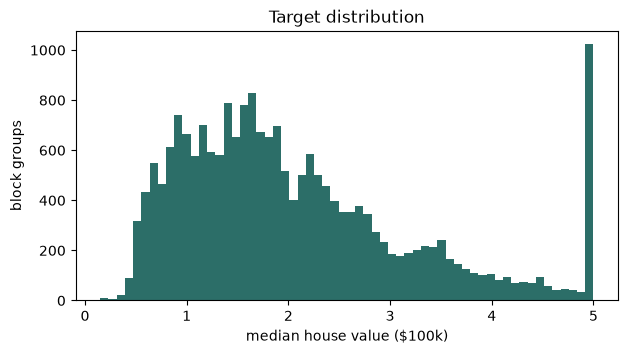

max value = 5.00001; 965 rows (4.7%) sit exactly at that cap


In [2]:
target = df["MedHouseVal"]
cap = target.max()
n_capped = int((target >= cap - 1e-6).sum())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(target, bins=60, color="#2C6E68")
ax.set_xlabel("median house value ($100k)")
ax.set_ylabel("block groups")
ax.set_title("Target distribution")
plt.show()

print(f"max value = {cap:.5f}; {n_capped} rows ({n_capped / len(df):.1%}) sit exactly at that cap")

The spike at the right edge is the **capped target**: every district worth more than about $500k is recorded as the cap. A linear model can never predict "above the cap" correctly for those rows, which limits how well it can do at the high end.

## 2. Which features move together?

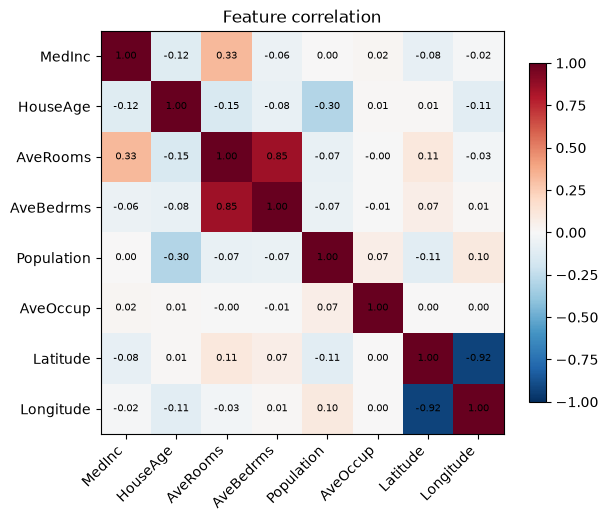

Latitude  Longitude   -0.925
AveRooms  AveBedrms    0.848
MedInc    AveRooms     0.327
dtype: float64

In [3]:
features = [c for c in df.columns if c != "MedHouseVal"]
corr = df[features].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Feature correlation")
plt.show()

pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .sort_values(key=abs, ascending=False)
)
pairs.head(3).round(3)

Strongly correlated pairs (the table above lists the top three) make the cost surface a long, narrow valley, so gradient descent converges slowly along one direction. This is why the learned weights of such features take the longest to match scikit-learn in `src/run_experiment.py`.

## 3. Does location matter?

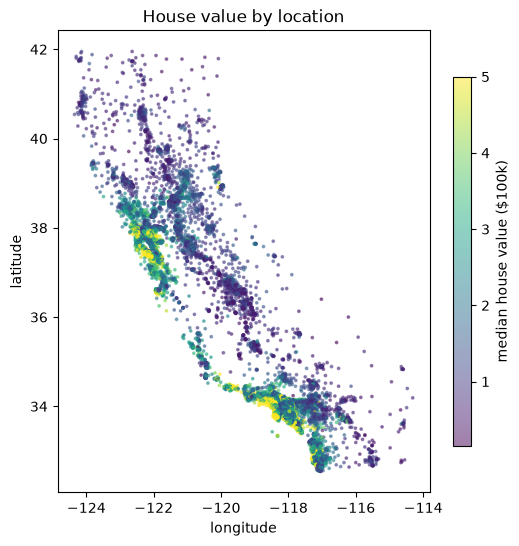

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(df["Longitude"], df["Latitude"], c=target, s=3, alpha=0.5, cmap="viridis")
fig.colorbar(sc, label="median house value ($100k)", shrink=0.8)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("House value by location")
plt.show()

The map traces the California coast: value is high near the coast and in a few metro areas, lower inland. A linear model uses latitude and longitude as two straight-line effects, so it cannot represent "close to the coast" or "this metro area". Ideas for improving this are listed in the project README under *Limitations and next steps*.

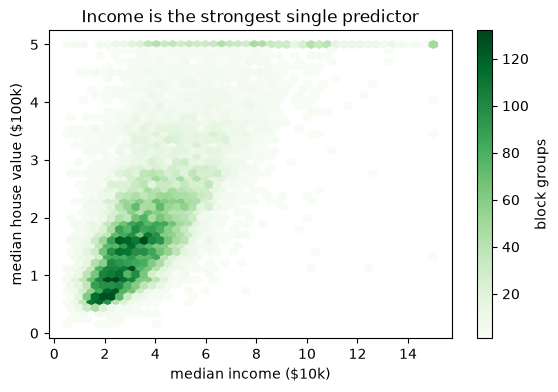

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
hb = ax.hexbin(df["MedInc"], target, gridsize=45, cmap="Greens", mincnt=1)
fig.colorbar(hb, label="block groups")
ax.set_xlabel("median income ($10k)")
ax.set_ylabel("median house value ($100k)")
ax.set_title("Income is the strongest single predictor")
plt.show()